In [1]:
import torch
import torchvision

import numpy as np
import matplotlib.pyplot as plt

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
import os
from google.colab import userdata

# 토큰 가져오기
try:
    kaggle_token = userdata.get('KAGGLE_TOKEN')
except Exception as e:
    print("코랩 시크릿에 KAGGLE_TOKEN이 설정되지 않았거나 접근 권한이 없습니다.")
    raise e

# 인증 토큰 파일 생성 및 권한 설정
!mkdir -p ~/.kaggle

# 가져온 토큰 변수를 사용해 access_token 파일 생성
with open('/root/.kaggle/access_token', 'w') as f:
    f.write(kaggle_token)

!chmod 600 ~/.kaggle/access_token

# 캐글 라이브러리 설치 및 다운로드
!pip install -q kaggle

os.makedirs('/root/work/data_augmentation/data', exist_ok=True)
%cd /root/work/data_augmentation/data

!kaggle datasets download -d jessicali9530/stanford-dogs-dataset
!unzip -q stanford-dogs-dataset.zip

/root/work/data_augmentation/data
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/stanford-dogs-dataset
License(s): other
100% 750M/750M [00:05<00:00, 143MB/s]



## 데이터셋

Oxford-IIIT Pet 이미지를 견종별 폴더에서 불러와 데이터 증강 실험에 사용합니다.

In [4]:
import os

dataset_dir = os.path.expanduser("~/work/data_augmentation/data/images/Images/")

# 견종 목록 가져오기
breed_folders = sorted([f for f in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, f))])

breed_counts = {}
for breed in breed_folders:
    breed_path = os.path.join(dataset_dir, breed)
    # 폴더 안의 이미지 파일 개수 세기
    images = [f for f in os.listdir(breed_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    breed_counts[breed] = len(images)

print(f"총 클래스(견종) 수: {len(breed_counts)}개 \n")

print("견종별 이미지 개수:")
for breed, count in breed_counts.items():
    print(f"- {breed}: {count}장")

# 가장 데이터가 많고 적은 견종 확인
if breed_counts:
    most_common = max(breed_counts.items(), key=lambda x: x[1])
    least_common = min(breed_counts.items(), key=lambda x: x[1])
    print(f"\n가장 많은 데이터를 가진 견종: {most_common[0]} ({most_common[1]}장)")
    print(f"가장 적은 데이터를 가진 견종: {least_common[0]} ({least_common[1]}장)")

총 클래스(견종) 수: 120개 

견종별 이미지 개수:
- n02085620-Chihuahua: 152장
- n02085782-Japanese_spaniel: 185장
- n02085936-Maltese_dog: 252장
- n02086079-Pekinese: 149장
- n02086240-Shih-Tzu: 214장
- n02086646-Blenheim_spaniel: 188장
- n02086910-papillon: 196장
- n02087046-toy_terrier: 172장
- n02087394-Rhodesian_ridgeback: 172장
- n02088094-Afghan_hound: 239장
- n02088238-basset: 175장
- n02088364-beagle: 195장
- n02088466-bloodhound: 187장
- n02088632-bluetick: 171장
- n02089078-black-and-tan_coonhound: 159장
- n02089867-Walker_hound: 153장
- n02089973-English_foxhound: 157장
- n02090379-redbone: 148장
- n02090622-borzoi: 151장
- n02090721-Irish_wolfhound: 218장
- n02091032-Italian_greyhound: 182장
- n02091134-whippet: 187장
- n02091244-Ibizan_hound: 188장
- n02091467-Norwegian_elkhound: 196장
- n02091635-otterhound: 151장
- n02091831-Saluki: 200장
- n02092002-Scottish_deerhound: 232장
- n02092339-Weimaraner: 160장
- n02093256-Staffordshire_bullterrier: 155장
- n02093428-American_Staffordshire_terrier: 164장
- n02093647-Bedlin

In [5]:
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from torchvision.models import ResNet50_Weights

# ResNet50이 사전학습할 때 사용한 이미지 전처리에서 평균과 표준편차를 가져옴
weights = ResNet50_Weights.DEFAULT

MEAN = weights.transforms().mean
STD = weights.transforms().std

def get_transform(mode='baseline', train=True):
    # 학습 데이터셋에만 데이터 증강 적용
    if not train:
        return transforms.Compose([
            transforms.Resize(232),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    if mode == 'baseline':
        return transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    elif mode == 'aug1':
        return transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(10),
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    elif mode == 'aug2':
        return transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2,
                hue=0.05
            ),
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    else:
        raise ValueError(f"Unknown transform mode: {mode}")

In [6]:
import os
from sklearn.model_selection import train_test_split

# 데이터셋 저장 경로
dataset_dir = os.path.expanduser("/root/work/data_augmentation/data/images/Images")

# 변환 없이 데이터셋 읽기
base_dataset = ImageFolder(dataset_dir)

# 전체 이미지 인덱스와 각 이미지의 품종 라벨
indices = list(range(len(base_dataset)))
labels = base_dataset.targets

# 품종별 비율을 유지하며 8:2로 분할
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("전체 이미지:", len(base_dataset))
print("훈련 이미지:", len(train_indices))
print("테스트 이미지:", len(test_indices))

전체 이미지: 20580
훈련 이미지: 16464
테스트 이미지: 4116


In [7]:
def build_loader(indices, transform, dataset_dir, batch_size=32, shuffle=False):
    dataset = ImageFolder(dataset_dir, transform=transform)

    subset = Subset(dataset, indices)

    loader = DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=False
    )

    return loader

In [8]:
baseline_train_loader = build_loader(
    train_indices,
    get_transform('baseline', train=True),
    dataset_dir,
    batch_size=32,
    shuffle=True
)

aug1_train_loader = build_loader(
    train_indices,
    get_transform("aug1", train=True),
    dataset_dir,
    batch_size=32,
    shuffle=True
)

aug2_train_loader = build_loader(
    train_indices,
    get_transform("aug2", train=True),
    dataset_dir,
    batch_size=32,
    shuffle=True
)

test_loader = build_loader(
    test_indices,
    get_transform("baseline", train=False),
    dataset_dir,
    batch_size=32,
    shuffle=False
)

In [9]:
ds_info = {
    "class_names": base_dataset.classes,
    "num_classes": len(base_dataset.classes)
}

In [10]:
def get_clip_box(image):
    _, H, W = image.shape

    # 크롭 영역의 기준이 될 중심점 좌표 (x, y)를 무작위로 선택
    x = torch.randint(0, W, (1,)).item()
    y = torch.randint(0, H, (1,)).item()

    # 바운딩 박스의 너비와 높이 결정 (max 함수를 통해 최소 1px 보장)
    width = max(1, int(W * torch.sqrt(1 - torch.rand(1)).item()))
    height = max(1, int(H * torch.sqrt(1 - torch.rand(1)).item()))

    # 중심점과 크기를 기준으로 좌표 계산
    x_min = max(0, x - width // 2)
    y_min = max(0, y - height // 2)
    x_max = min(W, x + width // 2 + 1)
    y_max = min(H, y + height // 2 + 1)

    return x_min, y_min, x_max, y_max

In [11]:
def cutmix(images, labels):
    # images.size(0): 배치에 포함된 이미지 수(32)
    # torch.randperm(32): 0부터 31까지의 숫자를 무작위 순서로 섞음
    # .to(images.device): 인덱스를 이미지와 같은 장치(CPU 또는 GPU)로 이동
    rand_index = torch.randperm(images.size(0)).to(images.device)

    x1, y1, x2, y2 = get_clip_box(images[0])

    mixed_images = images.clone()
    # 바운딩 박스에 무작위로 섞은(rand_index) 이미지 패치를 덮어씌움
    mixed_images[:, :, y1:y2, x1:x2] = images[rand_index, :, y1:y2, x1:x2]

    # 잘라 붙인 패치의 실제 면적을 반영해 원본 이미지 비율(lam) 계산
    cut_area = (x2 - x1) * (y2 - y1)
    total_area = images.size(2) * images.size(3)
    lam = 1 - cut_area / total_area

    return mixed_images, labels, labels[rand_index], lam

In [12]:
def mixup(images, labels, alpha=1.0):
  # 베타 분포에서 0과 1 사이의 숫자 생성
  # alpha = 1.0: 0~1 사이에서 비교적 균등하게 비율을 뽑음
  # alpha가 커지면 0.5 근처의 비율이 더 자주 뽑힘
  # alpha가 작아지면 0이나 1에 가까운 비율이 더 자주 뽑힘
  lam = np.random.beta(alpha, alpha)
  lam = max(lam, 1 - lam)   # 항상 lam이 0.5 이상

  rand_index = torch.randperm(images.size(0)).to(images.device)

  # 두 이미지를 비율에 따라 투명하게 합성
  mixed_images = lam*images + (1-lam)*images[rand_index]

  # 원본 레이블과 섞인 이미지의 레이블 분리
  labels_a = labels
  labels_b = labels[rand_index]

  return mixed_images, labels_a, labels_b, lam

In [13]:
import torch.nn as nn
import torchvision.models as models

num_classes = len(ds_info["class_names"])

def create_resnet50(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

baseline_model  = create_resnet50(num_classes).to(device)
aug1_model      = create_resnet50(num_classes).to(device)
aug2_model      = create_resnet50(num_classes).to(device)
mixup_model     = create_resnet50(num_classes).to(device)
cutmix_model    = create_resnet50(num_classes).to(device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 81.6MB/s]


In [14]:
criterion = nn.CrossEntropyLoss()

baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=1e-4
)

aug1_optimizer = torch.optim.Adam(
    aug1_model.parameters(),
    lr=1e-4
)

aug2_optimizer = torch.optim.Adam(
    aug2_model.parameters(),
    lr=1e-4
)

mixup_optimizer = torch.optim.Adam(
    mixup_model.parameters(),
    lr=1e-4
)

cutmix_optimizer = torch.optim.Adam(
    cutmix_model.parameters(),
    lr=1e-4
)

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0   # 배치 손실 누적
    correct = 0          # 정답을 맞힌 이미지 수
    total = 0            # 지금까지 처리한 전체 이미지 수

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)   # [32, 120]
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)    # 배치 전체 손실 계산을 위해 배치 크기 곱함 (마지막 배치는 32 이하일 수 있음)

        _, predicted = outputs.max(1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [16]:
def train_one_epoch_cutmix(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        images, labels_a, labels_b, lam = cutmix(images, labels)

        optimizer.zero_grad()
        outputs = model(images)
        # 두 레이블의 손실을 이미지 혼합 비율에 따라 결합
        loss = (
            lam * criterion(outputs, labels_a) + (1 - lam) * criterion(outputs, labels_b)
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)
        correct += (
            lam * (predicted == labels_a).sum().item() + (1 - lam) * (predicted == labels_b).sum().item()
        )
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [17]:
def train_one_epoch_mixup(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        images, labels_a, labels_b, lam = mixup(images, labels)

        optimizer.zero_grad()
        outputs = model(images)

        # 두 레이블의 손실을 이미지 혼합 비율에 따라 결합
        loss = (
            lam * criterion(outputs, labels_a) + (1 - lam) * criterion(outputs, labels_b)
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)
        correct += (
            lam * (predicted == labels_a).sum().item() + (1 - lam) * (predicted == labels_b).sum().item()
        )
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [18]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [19]:
import os

def fit(model, train_loader, val_loader, criterion, optimizer, device, epochs, train_fn=train_one_epoch):

  history = {
      "train_loss": [],
      "train_acc": [],
      "val_loss": [],
      "val_acc": []
      }

  for epoch in range(epochs):
    train_loss, train_acc = train_fn(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
        )

  return history

In [20]:
epochs = 10

In [21]:
baseline_history = fit(
    model=baseline_model,
    train_loader=baseline_train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=baseline_optimizer,
    device=device,
    epochs=epochs,
    train_fn=train_one_epoch
)

Epoch [1/10] Train Loss: 1.7441 Train Acc: 0.5980 Val Loss: 0.8996 Val Acc: 0.7366
Epoch [2/10] Train Loss: 0.6208 Train Acc: 0.8213 Val Loss: 0.7790 Val Acc: 0.7726
Epoch [3/10] Train Loss: 0.3315 Train Acc: 0.9012 Val Loss: 0.8099 Val Acc: 0.7592
Epoch [4/10] Train Loss: 0.2074 Train Acc: 0.9402 Val Loss: 0.8757 Val Acc: 0.7459
Epoch [5/10] Train Loss: 0.1563 Train Acc: 0.9556 Val Loss: 0.9358 Val Acc: 0.7398
Epoch [6/10] Train Loss: 0.1309 Train Acc: 0.9650 Val Loss: 0.9198 Val Acc: 0.7473
Epoch [7/10] Train Loss: 0.1368 Train Acc: 0.9606 Val Loss: 1.1749 Val Acc: 0.6883
Epoch [8/10] Train Loss: 0.1402 Train Acc: 0.9589 Val Loss: 1.1618 Val Acc: 0.7138
Epoch [9/10] Train Loss: 0.0933 Train Acc: 0.9732 Val Loss: 1.1460 Val Acc: 0.7174
Epoch [10/10] Train Loss: 0.0955 Train Acc: 0.9717 Val Loss: 1.0970 Val Acc: 0.7303


In [22]:
aug1_history = fit(
    model=aug1_model,
    train_loader=aug1_train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=aug1_optimizer,
    device=device,
    epochs=epochs,
    train_fn=train_one_epoch
)

Epoch [1/10] Train Loss: 1.8027 Train Acc: 0.5808 Val Loss: 0.8629 Val Acc: 0.7478
Epoch [2/10] Train Loss: 0.8375 Train Acc: 0.7596 Val Loss: 0.7684 Val Acc: 0.7711
Epoch [3/10] Train Loss: 0.6128 Train Acc: 0.8161 Val Loss: 0.7946 Val Acc: 0.7522
Epoch [4/10] Train Loss: 0.4849 Train Acc: 0.8529 Val Loss: 0.8202 Val Acc: 0.7417
Epoch [5/10] Train Loss: 0.3866 Train Acc: 0.8794 Val Loss: 0.8327 Val Acc: 0.7580
Epoch [6/10] Train Loss: 0.3201 Train Acc: 0.8987 Val Loss: 0.8063 Val Acc: 0.7668
Epoch [7/10] Train Loss: 0.2602 Train Acc: 0.9193 Val Loss: 0.9110 Val Acc: 0.7483
Epoch [8/10] Train Loss: 0.2195 Train Acc: 0.9320 Val Loss: 0.8902 Val Acc: 0.7583
Epoch [9/10] Train Loss: 0.2211 Train Acc: 0.9327 Val Loss: 1.0586 Val Acc: 0.7310
Epoch [10/10] Train Loss: 0.2079 Train Acc: 0.9374 Val Loss: 0.9740 Val Acc: 0.7519


In [23]:
aug2_history = fit(
    model=aug2_model,
    train_loader=aug2_train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=aug2_optimizer,
    device=device,
    epochs=epochs,
    train_fn=train_one_epoch
)

Epoch [1/10] Train Loss: 1.7845 Train Acc: 0.5911 Val Loss: 0.8541 Val Acc: 0.7466
Epoch [2/10] Train Loss: 0.6713 Train Acc: 0.8079 Val Loss: 0.7876 Val Acc: 0.7529
Epoch [3/10] Train Loss: 0.3632 Train Acc: 0.8942 Val Loss: 0.7786 Val Acc: 0.7658
Epoch [4/10] Train Loss: 0.2267 Train Acc: 0.9339 Val Loss: 0.8693 Val Acc: 0.7507
Epoch [5/10] Train Loss: 0.1793 Train Acc: 0.9481 Val Loss: 0.9336 Val Acc: 0.7391
Epoch [6/10] Train Loss: 0.1566 Train Acc: 0.9566 Val Loss: 1.0144 Val Acc: 0.7289
Epoch [7/10] Train Loss: 0.1409 Train Acc: 0.9591 Val Loss: 1.0291 Val Acc: 0.7349
Epoch [8/10] Train Loss: 0.1371 Train Acc: 0.9606 Val Loss: 0.9482 Val Acc: 0.7532
Epoch [9/10] Train Loss: 0.1095 Train Acc: 0.9669 Val Loss: 1.0517 Val Acc: 0.7328
Epoch [10/10] Train Loss: 0.1178 Train Acc: 0.9661 Val Loss: 1.0869 Val Acc: 0.7318


In [24]:
cutmix_history = fit(
    model=cutmix_model,
    train_loader=baseline_train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=cutmix_optimizer,
    device=device,
    epochs=epochs,
    train_fn=train_one_epoch_cutmix
)

Epoch [1/10] Train Loss: 3.2576 Train Acc: 0.3134 Val Loss: 1.1765 Val Acc: 0.6927
Epoch [2/10] Train Loss: 2.4984 Train Acc: 0.4560 Val Loss: 0.9953 Val Acc: 0.7403
Epoch [3/10] Train Loss: 2.3007 Train Acc: 0.5040 Val Loss: 0.8685 Val Acc: 0.7602
Epoch [4/10] Train Loss: 2.1123 Train Acc: 0.5428 Val Loss: 0.9175 Val Acc: 0.7609
Epoch [5/10] Train Loss: 1.9504 Train Acc: 0.5796 Val Loss: 0.9300 Val Acc: 0.7561
Epoch [6/10] Train Loss: 1.9302 Train Acc: 0.5867 Val Loss: 0.9589 Val Acc: 0.7556
Epoch [7/10] Train Loss: 1.8423 Train Acc: 0.6051 Val Loss: 0.9108 Val Acc: 0.7634
Epoch [8/10] Train Loss: 1.7912 Train Acc: 0.6114 Val Loss: 0.9526 Val Acc: 0.7714
Epoch [9/10] Train Loss: 1.6997 Train Acc: 0.6342 Val Loss: 0.9435 Val Acc: 0.7558
Epoch [10/10] Train Loss: 1.7035 Train Acc: 0.6218 Val Loss: 1.0337 Val Acc: 0.7420


In [25]:
mixup_history = fit(
    model=mixup_model,
    train_loader=baseline_train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=mixup_optimizer,
    device=device,
    epochs=epochs,
    train_fn=train_one_epoch_mixup
)

Epoch [1/10] Train Loss: 3.0278 Train Acc: 0.3761 Val Loss: 1.1461 Val Acc: 0.7143
Epoch [2/10] Train Loss: 2.3721 Train Acc: 0.5259 Val Loss: 0.9658 Val Acc: 0.7308
Epoch [3/10] Train Loss: 2.2608 Train Acc: 0.5593 Val Loss: 1.0181 Val Acc: 0.7512
Epoch [4/10] Train Loss: 2.1491 Train Acc: 0.5925 Val Loss: 0.9844 Val Acc: 0.7493
Epoch [5/10] Train Loss: 2.0159 Train Acc: 0.6268 Val Loss: 0.9966 Val Acc: 0.7507
Epoch [6/10] Train Loss: 1.9796 Train Acc: 0.6424 Val Loss: 1.0384 Val Acc: 0.7379
Epoch [7/10] Train Loss: 1.8987 Train Acc: 0.6607 Val Loss: 1.0253 Val Acc: 0.7490
Epoch [8/10] Train Loss: 1.8093 Train Acc: 0.6813 Val Loss: 0.9987 Val Acc: 0.7437
Epoch [9/10] Train Loss: 1.8359 Train Acc: 0.6759 Val Loss: 1.0558 Val Acc: 0.7461
Epoch [10/10] Train Loss: 1.8258 Train Acc: 0.6775 Val Loss: 1.0590 Val Acc: 0.7415


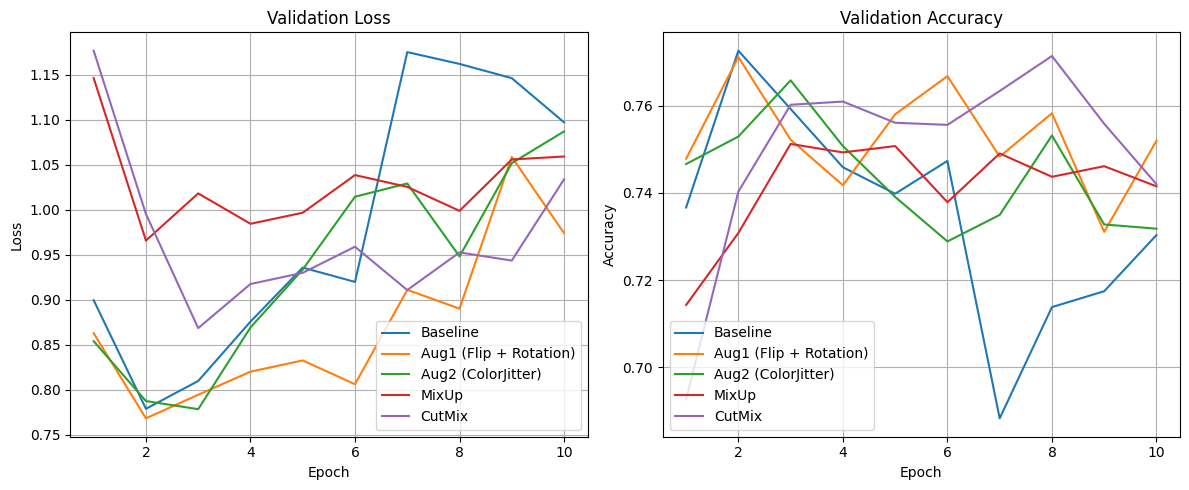

In [28]:
import matplotlib.pyplot as plt

def plot_history(baseline_history, aug1_history, aug2_history, mixup_history, cutmix_history):

    epochs = range(1, len(baseline_history["train_loss"]) + 1)

    plt.figure(figsize=(12, 5))

    # 검증 데이터 손실
    plt.subplot(1, 2, 1)
    plt.plot(epochs, baseline_history["val_loss"], label="Baseline")
    plt.plot(epochs, aug1_history["val_loss"], label="Aug1 (Flip + Rotation)")
    plt.plot(epochs, aug2_history["val_loss"], label="Aug2 (ColorJitter)")
    plt.plot(epochs, mixup_history["val_loss"], label="MixUp")
    plt.plot(epochs, cutmix_history["val_loss"], label="CutMix")
    plt.title("Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    # 검증 데이터 정확도
    plt.subplot(1, 2, 2)
    plt.plot(epochs, baseline_history["val_acc"], label="Baseline")
    plt.plot(epochs, aug1_history["val_acc"], label="Aug1 (Flip + Rotation)")
    plt.plot(epochs, aug2_history["val_acc"], label="Aug2 (ColorJitter)")
    plt.plot(epochs, mixup_history["val_acc"], label="MixUp")
    plt.plot(epochs, cutmix_history["val_acc"], label="CutMix")
    plt.title("Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


plot_history(baseline_history, aug1_history, aug2_history, mixup_history, cutmix_history)

In [29]:
import pandas as pd

# 마지막 epoch 성능 표
result = pd.DataFrame({
    "Model": [
        "Baseline",
        "Aug1 (Flip+Rotation)",
        "Aug2 (ColorJitter)",
        "MixUp",
        "CutMix"
    ],
    "Train Loss": [
        baseline_history["train_loss"][-1],
        aug1_history["train_loss"][-1],
        aug2_history["train_loss"][-1],
        mixup_history["train_loss"][-1],
        cutmix_history["train_loss"][-1],
    ],
    "Train Acc": [
        baseline_history["train_acc"][-1],
        aug1_history["train_acc"][-1],
        aug2_history["train_acc"][-1],
        mixup_history["train_acc"][-1],
        cutmix_history["train_acc"][-1],
    ],
    "Val Loss": [
        baseline_history["val_loss"][-1],
        aug1_history["val_loss"][-1],
        aug2_history["val_loss"][-1],
        mixup_history["val_loss"][-1],
        cutmix_history["val_loss"][-1],
    ],
    "Val Acc": [
        baseline_history["val_acc"][-1],
        aug1_history["val_acc"][-1],
        aug2_history["val_acc"][-1],
        mixup_history["val_acc"][-1],
        cutmix_history["val_acc"][-1],
    ],
})


result = result.round(4)

result

,Model,Train Loss,Train Acc,Val Loss,Val Acc
0,Baseline,0.0955,0.9717,1.0970,0.7303
1,Aug1 (Flip+Rotation),0.2079,0.9374,0.9740,0.7519
2,Aug2 (ColorJitter),0.1178,0.9661,1.0869,0.7318
3,MixUp,1.8258,0.6775,1.0590,0.7415
4,CutMix,1.7035,0.6218,1.0337,0.7420
